## Садиков_3826М1ПМвм1_2
### Лабораторная работа 2: Линейная регрессия
### Садиков Дамир. 3821М1ПМвм1. 2026

In [1]:
import sys
print(sys.version)

3.10.4 (tags/v3.10.4:9d38120, Mar 23 2022, 23:13:41) [MSC v.1929 64 bit (AMD64)]


## Цель работы

Цель практической работы — закрепить теоретические знания по линейной регрессии и освоить практические навыки построения, диагностики и улучшения регрессионных моделей на реальных данных о стоимости квартир Нижнего Новгорода

Для достижения целей работы будут выполнены следующие задания:
1. Конструирование признаков на основе площади и количества комнат
2. Диагностика остатков и проверка гипотез линейной модели
3. Кросс-валидация и сравнение схем разбиения
4. Устойчивость модели к выбросам: сравнение МНК, Huber и квантильной регрессии
5. Анализ ошибок по подгруппам и поиск «сложных» сегментов
6. Полиномиальные признаки и борьба с переобучением
7. Логарифмирование целевой переменной и интерпретация коэффициентов

## Считывание и очистка датасета

Загрузка сырых данных

In [2]:
import pandas as pd
url = "flats.csv"
data_raw = pd.read_csv(url)
print("Размер датасета:", data_raw.shape)
display(data_raw.head())
data_raw.info()

Размер датасета: (72379, 10)


,Price,Date,Lat,Lng,Type,Floors,Building,Rooms,Floor,Area
0,3500.0,240,56.365696,43.820250,Resale,9.0,Brick,3.0,4.0,60.0
1,4000.0,240,56.323057,44.007862,Resale,3.0,Brick,3.0,3.0,57.0
2,2150.0,240,56.267552,43.892107,Resale,5.0,Panel,2.0,1.0,38.0
3,3100.0,240,56.359963,43.813756,Resale,5.0,Panel,4.0,2.0,59.0
4,3585.0,240,56.325374,43.937463,Resale,9.0,Panel,2.0,7.0,52.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72379 entries, 0 to 72378
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Price     72379 non-null  float64
 1   Date      72379 non-null  int64  
 2   Lat       72379 non-null  float64
 3   Lng       72379 non-null  float64
 4   Type      72362 non-null  object 
 5   Floors    72362 non-null  float64
 6   Building  72362 non-null  object 
 7   Rooms     72362 non-null  float64
 8   Floor     72362 non-null  float64
 9   Area      72362 non-null  float64
dtypes: float64(7), int64(1), object(2)
memory usage: 5.5+ MB


Очистка датасета

In [3]:
data = data_raw.copy()
# Рассмотрим строки с пропущенными значениями
data[data.isna().any(axis=1)]

,Price,Date,Lat,Lng,Type,Floors,Building,Rooms,Floor,Area
4777,1400.0,56,56.326783,44.002687,NaN,NaN,NaN,NaN,NaN,NaN
4778,3000.0,57,56.229416,43.946365,NaN,NaN,NaN,NaN,NaN,NaN
4824,4950.0,62,56.283934,44.035397,NaN,NaN,NaN,NaN,NaN,NaN
4826,4100.0,56,56.341398,43.841083,NaN,NaN,NaN,NaN,NaN,NaN
4827,2900.0,56,56.272180,43.933501,NaN,NaN,NaN,NaN,NaN,NaN
4852,2400.0,56,56.327955,43.849715,NaN,NaN,NaN,NaN,NaN,NaN
5813,6000.0,62,56.283864,44.075417,NaN,NaN,NaN,NaN,NaN,NaN
5814,2350.0,62,56.326604,43.932114,NaN,NaN,NaN,NaN,NaN,NaN
6681,2950.0,62,56.348068,43.908636,NaN,NaN,NaN,NaN,NaN,NaN
6682,2390.0,63,56.201114,43.810028,NaN,NaN,NaN,NaN,NaN,NaN


Поскольку строк с пропущенными значениями незначительное количество относительно всей выборке и в них утрачены сразу многие значимые признаки, то проще всего исключить эти строки из рассмотрения

In [4]:
data = data.dropna()

Удалим дубликаты:

In [5]:
print("Количество дубликатов:", data.duplicated().sum())
data = data.drop_duplicates()

Количество дубликатов: 1210


Применим One-Hot Кодирование для категориальных признаков

In [6]:
display(data['Building'].unique())
display(data['Building'].unique())

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded = encoder.fit_transform(data[['Building', 'Type']])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(),
    index=data.index
)

data = pd.concat([data.drop(columns=['Building', 'Type']), encoded_df], axis=1)

array(['Brick', 'Panel', 'Block', 'Monolithic', 'Wooden'], dtype=object)

array(['Brick', 'Panel', 'Block', 'Monolithic', 'Wooden'], dtype=object)

Борьба с выбросами. Ожидаем увидеть зависимость прежде всего между площадью и ценой. Поэтому рассмотрим диаграмму рассеивания по этим признакам

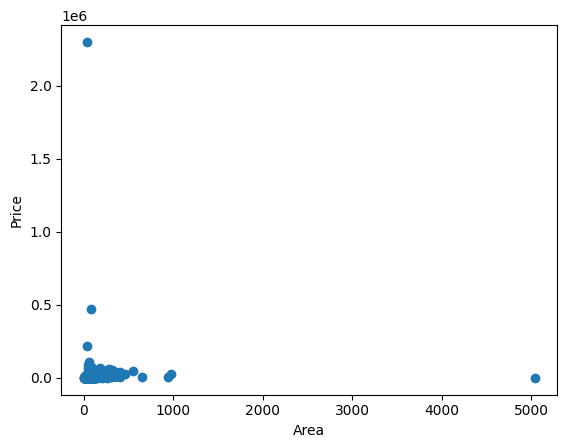

In [7]:
import matplotlib.pyplot as plt
plt.scatter(x='Area', y='Price', data=data)
plt.xlabel('Area')
plt.ylabel('Price')
pass

Из диаграммы рассеивания видно что в выборке присутствуют выбросы: объекты, значения площади или цены которых значительно отличаются от основной массы объектов. Удалим выбросы, выходящие за границы квантилей 0.005 и 0.995.

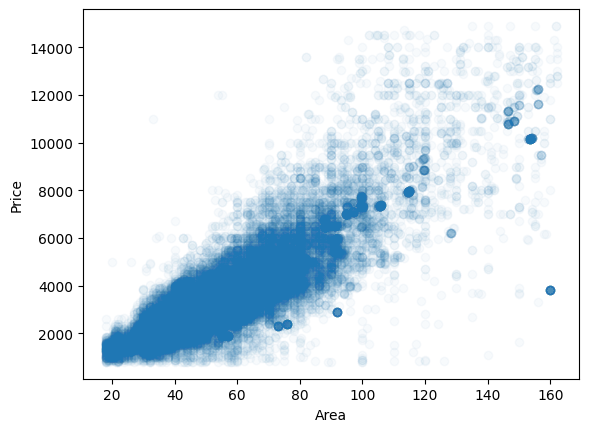

In [8]:
rows_to_drop = data[
    (data['Price'] < data['Price'].quantile(0.005)) |
    (data['Price'] > data['Price'].quantile(0.995)) |
    (data['Area'] < data['Area'].quantile(0.005)) |
    (data['Area'] > data['Area'].quantile(0.995))
].index
data = data.drop(rows_to_drop)
plt.scatter(x='Area', y='Price', data=data, alpha = .03)
plt.xlabel('Area')
plt.ylabel('Price')
pass

Теперь наглядно видно зависимость между площадью и ценой. Теперь проверим связь даты и цены

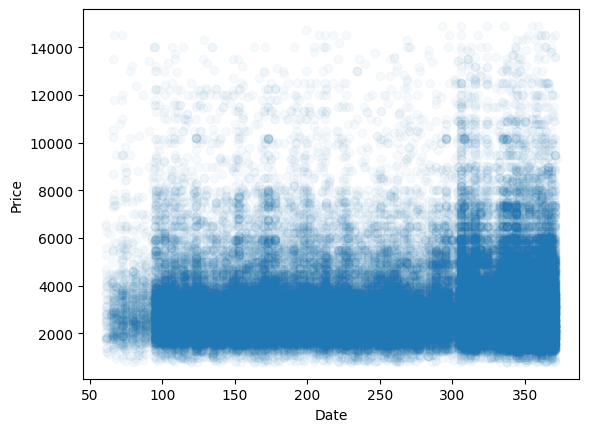

In [9]:
plt.scatter(x='Date', y='Price', data=data, alpha = .03)
plt.xlabel('Date')
plt.ylabel('Price')
pass

Из графика видно что полезной для нашей задачи связи даты и цены не наблюдается. Можем не использовать этот столбец в очищенном датасете

In [10]:
data = data.drop(columns=['Date'])

Проверим полученный датасет:

In [11]:
print("Размер исходного датасета:", data_raw.shape)
print("Размер очищенного датасета:", data.shape)

print("\nКоличество пропусков:")
print(data.isna().sum().sum())

print("\nТипы данных:")
print(data.dtypes)

display(data.head())

Размер исходного датасета: (72379, 10)
Размер очищенного датасета: (70045, 12)

Количество пропусков:
0

Типы данных:
Price                  float64
Lat                    float64
Lng                    float64
Floors                 float64
Rooms                  float64
Floor                  float64
Area                   float64
Building_Brick         float64
Building_Monolithic    float64
Building_Panel         float64
Building_Wooden        float64
Type_Resale            float64
dtype: object


,Price,Lat,Lng,Floors,Rooms,Floor,Area,Building_Brick,Building_Monolithic,Building_Panel,Building_Wooden,Type_Resale
0,3500.0,56.365696,43.820250,9.0,3.0,4.0,60.0,1.0,0.0,0.0,0.0,1.0
1,4000.0,56.323057,44.007862,3.0,3.0,3.0,57.0,1.0,0.0,0.0,0.0,1.0
2,2150.0,56.267552,43.892107,5.0,2.0,1.0,38.0,0.0,0.0,1.0,0.0,1.0
3,3100.0,56.359963,43.813756,5.0,4.0,2.0,59.0,0.0,0.0,1.0,0.0,1.0
4,3585.0,56.325374,43.937463,9.0,2.0,7.0,52.5,0.0,0.0,1.0,0.0,1.0


In [12]:
display(data.describe())

,Price,Lat,Lng,Floors,Rooms,Floor,Area,Building_Brick,Building_Monolithic,Building_Panel,Building_Wooden,Type_Resale
count,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000
mean,3312.172309,56.294946,43.935118,9.371761,1.945863,5.166993,52.385121,0.732029,0.063316,0.173431,0.003955,0.886616
std,1751.501577,0.044961,0.081732,5.123899,0.909084,3.863453,21.276194,0.442905,0.243533,0.378622,0.062762,0.317064
min,800.000000,54.862751,41.806470,1.000000,0.000000,1.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2200.000000,56.264893,43.868203,5.000000,1.000000,2.000000,37.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2850.000000,56.299806,43.931336,9.000000,2.000000,4.000000,46.000000,1.000000,0.000000,0.000000,0.000000,1.000000
75%,3850.000000,56.325200,44.005232,12.000000,3.000000,7.000000,63.000000,1.000000,0.000000,0.000000,0.000000,1.000000
max,14900.000000,57.127867,44.485489,25.000000,6.000000,25.000000,162.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Задание 1. Конструирование признаков на основе площади и количества комнат

Создание производных признаков:

In [13]:
import numpy as np
data_model = data.copy()

data_model['Area_per_room'] = data_model['Area'] / (data_model['Rooms'] + 1)
data_model['Is_studio'] = (data_model['Rooms'] == 0).astype(int)
data_model['Floor_ratio'] = data_model['Floor'] / data_model['Floors']
data_model['Is_first_floor'] = (data_model['Floor'] == 1).astype(int)
data_model['Is_last_floor'] = (data_model['Floor'] == data_model['Floors']).astype(int)
data_model['Log_area'] = np.log1p(data_model['Area'])

display(data_model)

,Price,Lat,Lng,Floors,Rooms,Floor,Area,Building_Brick,Building_Monolithic,Building_Panel,Building_Wooden,Type_Resale,Area_per_room,Is_studio,Floor_ratio,Is_first_floor,Is_last_floor,Log_area
0,3500.000,56.365696,43.820250,9.0,3.0,4.0,60.0,1.0,0.0,0.0,0.0,1.0,15.000000,0,0.444444,0,0,4.110874
1,4000.000,56.323057,44.007862,3.0,3.0,3.0,57.0,1.0,0.0,0.0,0.0,1.0,14.250000,0,1.000000,0,1,4.060443
2,2150.000,56.267552,43.892107,5.0,2.0,1.0,38.0,0.0,0.0,1.0,0.0,1.0,12.666667,0,0.200000,1,0,3.663562
3,3100.000,56.359963,43.813756,5.0,4.0,2.0,59.0,0.0,0.0,1.0,0.0,1.0,11.800000,0,0.400000,0,0,4.094345
4,3585.000,56.325374,43.937463,9.0,2.0,7.0,52.5,0.0,0.0,1.0,0.0,1.0,17.500000,0,0.777778,0,0,3.979682
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72374,3250.000,56.282006,44.085056,14.0,1.0,1.0,44.7,0.0,1.0,0.0,0.0,1.0,22.350000,0,0.071429,1,0,3.822098
72375,2824.800,56.348480,43.873340,17.0,1.0,3.0,42.8,1.0,0.0,0.0,0.0,1.0,21.400000,0,0.176471,0,0,3.779634
72376,3316.125,56.300964,43.951468,25.0,2.0,5.0,55.5,0.0,1.0,0.0,0.0,0.0,18.500000,0,0.200000,0,0,4.034241
72377,13600.000,56.329327,44.014997,5.0,3.0,4.0,81.9,1.0,0.0,0.0,0.0,1.0,20.475000,0,0.800000,0,0,4.417635


Единое разбиение на train/test для всех вариантов тестирования

In [14]:
from sklearn.model_selection import train_test_split
train_idx, test_idx = train_test_split(data_model.index, test_size=0.2, random_state=42)

Для удобства выделим признаки для каждой из рассматриваемых моделей:
- features_base - Для модели использующей исходные признаки
- features_plus - Для модели с добавленными признаками
- features_log - Для модели, в которой Area заменена на Log_area

In [15]:
target_feature = 'Price'

features_base = data.columns.tolist()
features_base.remove(target_feature)

features_plus = data_model.columns.tolist()
features_plus.remove(target_feature)

features_log = features_base.copy()
features_log[features_log.index('Area')] = 'Log_area'

print('Целевой признак:', target_feature)
print('Исходные признаки:', features_base)
print('С производынми признаками:', features_plus)
print('Area_log вместо area:', features_log)

Целевой признак: Price
Исходные признаки: ['Lat', 'Lng', 'Floors', 'Rooms', 'Floor', 'Area', 'Building_Brick', 'Building_Monolithic', 'Building_Panel', 'Building_Wooden', 'Type_Resale']
С производынми признаками: ['Lat', 'Lng', 'Floors', 'Rooms', 'Floor', 'Area', 'Building_Brick', 'Building_Monolithic', 'Building_Panel', 'Building_Wooden', 'Type_Resale', 'Area_per_room', 'Is_studio', 'Floor_ratio', 'Is_first_floor', 'Is_last_floor', 'Log_area']
Area_log вместо area: ['Lat', 'Lng', 'Floors', 'Rooms', 'Floor', 'Log_area', 'Building_Brick', 'Building_Monolithic', 'Building_Panel', 'Building_Wooden', 'Type_Resale']


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_metrics(features):
    X_train = data_model.loc[train_idx, features]
    X_test = data_model.loc[test_idx, features]
    y_train = data_model.loc[train_idx, target_feature]
    y_test = data_model.loc[test_idx, target_feature]

    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    predictions = lr_model.predict(X_test)

    metrics = {
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    }
    return lr_model, metrics

model_base, metrics_base = calculate_metrics(features_base)
model_plus, metrics_plus = calculate_metrics(features_plus)
model_log, metrics_log = calculate_metrics(features_log)
print('Метрики для базовой модели:\n', metrics_base)
print('Метрики для модели c добавленными признаками:\n', metrics_plus)
print('Метрики для модели с Log_area:\n', metrics_log)

Метрики для базовой модели:
 {'MAE': 484.92042341031487, 'RMSE': 788.6315457023416, 'R2': 0.7974592900276681}
Метрики для модели c добавленными признаками:
 {'MAE': 470.6615570531687, 'RMSE': 776.6066742146207, 'R2': 0.8035887882778016}
Метрики для модели с Log_area:
 {'MAE': 609.4444957993652, 'RMSE': 937.7689827561372, 'R2': 0.713611373916601}


In [17]:
coefs = pd.DataFrame({
    'Feature': model_plus.feature_names_in_,
    'Coef': model_plus.coef_
})
#coefs = coefs[coefs['Feature'].isin(['Area_per_room', 'Is_studio', 'Floor_ratio', 'Is_first_floor', 'Is_last_floor', 'Log_area'])]

coefs = coefs.sort_values(
    by='Coef',
    key=abs,
    ascending=False
)

display(coefs)

,Feature,Coef
1,Lng,2802.371763
0,Lat,1523.386245
9,Building_Wooden,-630.835698
3,Rooms,-605.014476
13,Floor_ratio,-589.820535
16,Log_area,-541.292517
14,Is_first_floor,-367.425016
10,Type_Resale,186.963203
8,Building_Panel,-111.516726
5,Area,100.686042


Согласно метрикам модель с производными признаками показала улучшение. Рассмотрим коэффициенты при производных признаках. Наиболее существенными оказались Floor_ratio, Log_area, Is_first_floor. Коэффициент при Is_first_floor, Is_last_floor	показывает что в типичном случае при прочих равных стоимость квартир на первом и последнем этажах несколько ниже. Логарифм от площади также имеет отрицательныей коэффициент, что должно смягчать влияение очень больших квартир на стоимость.
Использование логарифма площади вместо площади в третьей модели привело только к ухудшению результатов, так как теряется линейная зависимость между ценой и площадью

## Задание 2. Диагностика остатков и проверка гипотез линейной модели

Рассмотрим подробнее базовую модель (model_base из предыдущего задания)

In [18]:
X_test_base = data_model.loc[test_idx, features_base]
y_test = data_model.loc[test_idx, target_feature]

y_pred = model_base.predict(X_test_base)
residuals = y_test - y_pred

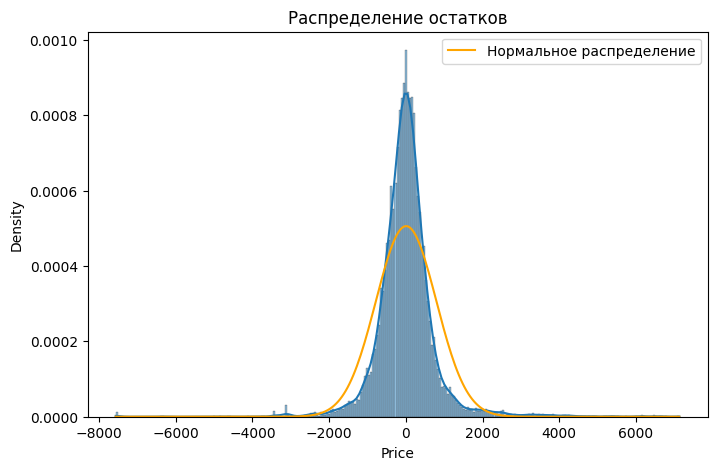

In [19]:
import numpy as np
import seaborn as sns
from scipy.stats import norm

x = np.linspace(residuals.min(), residuals.max(), 300)

plt.figure(figsize=(8, 5))
sns.histplot(residuals, stat='density', kde=True)
plt.plot(x, norm.pdf(x, residuals.mean(), residuals.std()),
         label='Нормальное распределение', color='orange')

plt.title('Распределение остатков')
plt.legend()
plt.show()

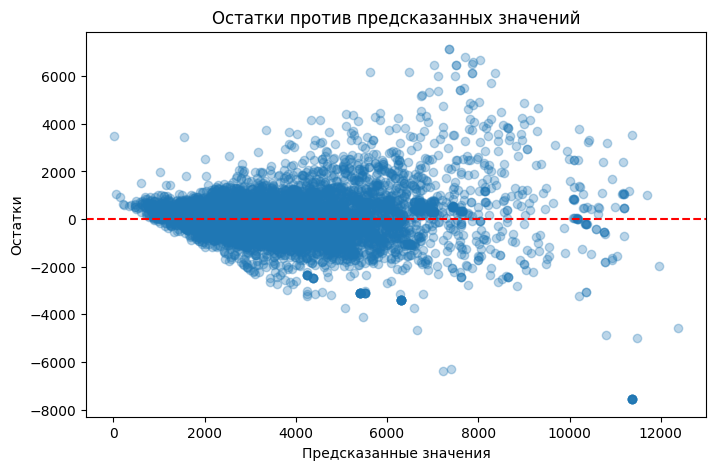

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Остатки против предсказанных значений')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.show()

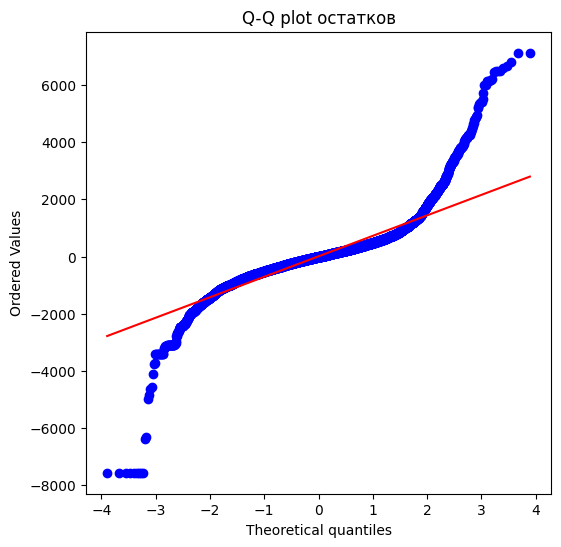

In [21]:
from scipy.stats import probplot

plt.figure(figsize=(6, 6))

probplot(residuals, dist='norm', plot=plt)

plt.title('Q-Q plot остатков')
plt.show()

Q-Q plot: значительные отклонения точек от диагональной линии на хвостах свидетельствуют о невыполнении гипотезы о нормальном распределении остатков.

In [22]:
corr = pd.Series(y_pred).corr(
    pd.Series(residuals.abs().values)
)

print(f'Корреляция: {corr:.4f}')

Корреляция: 0.4762


Проверка гетероскедастичности: наблюдалось увелечение разброса остатков при увелечении предсказаний, это прямое указание на гетероскедастичность. Наблюдаемая корреляция: 0.4801

In [23]:
mean_residual = residuals.mean()

print(f'Среднее остатков: {mean_residual:.4f}')

Среднее остатков: 7.4058


Смещение среднего остатков не значительно относительно велечины предсказаний

In [24]:
numeric_features = X_test_base.select_dtypes(include='number').columns

corr_residuals = X_test_base[numeric_features].corrwith(residuals)

corr_residuals = corr_residuals.sort_values(
    key=abs,
    ascending=False
)

display(corr_residuals.to_frame('Correlation with residuals'))

,Correlation with residuals
Area,0.021606
Rooms,0.018863
Floors,-0.016317
Type_Resale,0.014561
Lng,0.011554
Building_Monolithic,-0.011211
Building_Brick,0.010461
Building_Panel,-0.006801
Lat,0.005962
Building_Wooden,-0.005244


Не наблюдается значимой линейной корреляции между остатками и признаками

Гетероскедастичность и отклонение хвостов на Q-Q plot указывает на непостоянную дисперсию и отклонение
от нормальности. Таким образом не все предпосылки модели выполняются
Для борьбы с этими эффектами в последующих заданиях предлагается использовать логарифмирование цены (Price).

## Задание 3. Кросс-валидация и сравнение схем разбиения

In [25]:
target_feature = 'Price'
features = data.columns.drop(target_feature).tolist()

X = data[features]
y = data[target_feature]

Одиночное разбиение train/test 80/20

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

single_metrics = {
    'MAE': mean_absolute_error(y_test, y_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
    'R2': r2_score(y_test, y_pred)
}

print('Метрики на тестовой выборке (80/20):')
for metric, value in single_metrics.items():
    print(f'{metric}: {value:.4f}')

Метрики на тестовой выборке (80/20):
MAE: 484.9204
RMSE: 788.6315
R2: 0.7975


5-fold кросс-валидация

In [27]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    LinearRegression(), X, y,
    cv=cv,
    scoring={
        'NMAE': 'neg_mean_absolute_error',
        'NRMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    },
    return_train_score=False
)

cv_metrics = pd.DataFrame({
    'MAE': -cv_results['test_NMAE'],
    'RMSE': -cv_results['test_NRMSE'],
    'R2': cv_results['test_R2']
})

display(cv_metrics)
print('Среднее и стандартное отклонение по фолдам:')
for metric in cv_metrics.columns:
    print(f'{metric}: mean: {cv_metrics[metric].mean():.4f}; std: {cv_metrics[metric].std():.4f}')

,MAE,RMSE,R2
0,484.920423,788.631546,0.797459
1,484.080426,809.807125,0.788250
2,482.113948,773.717998,0.807883
3,489.881454,805.422689,0.781294
4,484.222019,784.215272,0.800869


Среднее и стандартное отклонение по фолдам:
MAE: mean: 485.0437; std: 2.8985
RMSE: mean: 792.3589; std: 15.0233
R2: mean: 0.7952; std: 0.0105


Повторное случайное разбиение

In [28]:
repeated_metrics = []

for random_state in range(100):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=random_state
    )
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    repeated_metrics.append({
        'R2': r2_score(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred))
    })

repeated_metrics = pd.DataFrame(repeated_metrics)
display(repeated_metrics.describe().loc[['mean', 'std', 'min', 'max']])

,R2,RMSE
mean,0.795932,790.946012
std,0.005498,11.527043
min,0.784298,760.048081
max,0.808430,828.814236


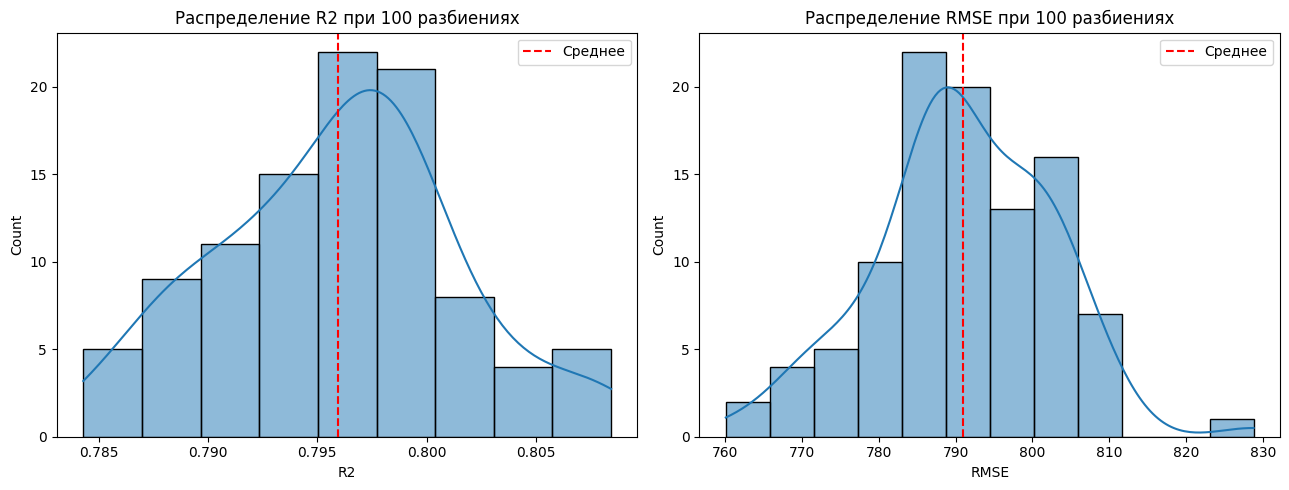

R2: mean: 0.7959, std: 0.0055
RMSE: mean: 790.9460, std: 11.5270


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(repeated_metrics['R2'], kde=True, ax=axes[0])
axes[0].axvline(repeated_metrics['R2'].mean(), color='red', linestyle='--', label='Среднее')
axes[0].set_title('Распределение R2 при 100 разбиениях')
axes[0].set_xlabel('R2')
axes[0].legend()

sns.histplot(repeated_metrics['RMSE'], kde=True, ax=axes[1])
axes[1].axvline(repeated_metrics['RMSE'].mean(), color='red', linestyle='--', label='Среднее')
axes[1].set_title('Распределение RMSE при 100 разбиениях')
axes[1].set_xlabel('RMSE')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"R2: mean: {repeated_metrics['R2'].mean():.4f}, std: {repeated_metrics['R2'].std():.4f}")
print(f"RMSE: mean: {repeated_metrics['RMSE'].mean():.4f}, std: {repeated_metrics['RMSE'].std():.4f}")


Проверка зависит ли качество от размера тестовой выборки

,test_size,RMSE,R2
0,0.10,782.938693,0.800097
1,0.15,789.434421,0.796203
2,0.20,788.606571,0.797461
3,0.25,795.942369,0.797292
4,0.30,798.100445,0.795097
5,0.35,792.581928,0.797676
6,0.40,799.317822,0.792813
7,0.45,794.144779,0.795243
8,0.50,792.872852,0.796453
9,0.55,788.963360,0.799423


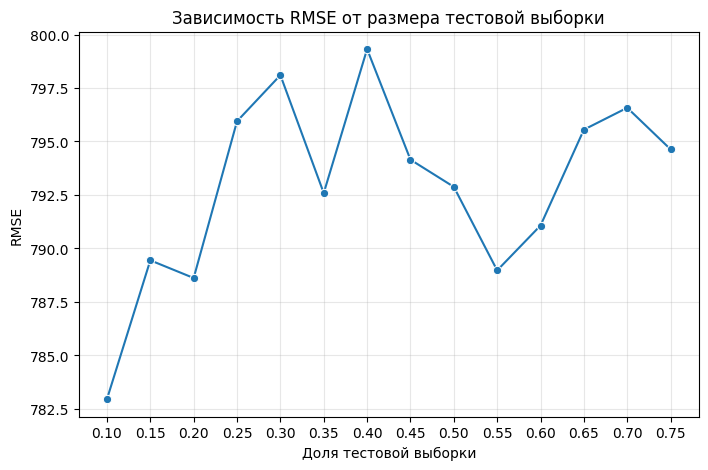

In [30]:
test_sizes = np.arange(0.1, 0.8, 0.05)
size_results = []

for test_size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    size_results.append({
        'test_size': test_size,
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    })

size_results = pd.DataFrame(size_results)
display(size_results)

plt.figure(figsize=(8, 5))
sns.lineplot(data=size_results, x='test_size', y='RMSE', marker='o')
plt.title('Зависимость RMSE от размера тестовой выборки')
plt.xlabel('Доля тестовой выборки')
plt.ylabel('RMSE')
plt.xticks(test_sizes)
plt.grid(alpha=0.3)
plt.show()


Результат тестирования по одиночному разбиению может варьироваться: результат зависит от того, какие именно объекты попали в тестовую выборку. Кросс-валидация и повторные разбиения уменьшают влияние этого случайного фактора, поскольку используют несколько вариантов разбиения. 5-fold кросс-валидация позволяет оценить качество на всех частях данных и получить среднее вместе с разбросом результатов

Размер тестовой выборки также влияет на оценку: при малом test_size метрика рассчитывается по меньшему числу объектов и может сильнее зависеть от состава теста, а при увеличении test_size, наоборот, оценка строится на большем числе объектов, но для обучения остаётся меньше данных. Поэтому зависимость RMSE от доли тестовой выборки не монотонная

Одиночное разбиение удобно для быстрой проверки, а повторные разбиения полезны как проверка чувствительности модели к случайному разбиению.
В данной задаче я бы рекомендовал 5-fold кросс-валидацию как основной способ оценки качества модели: она использует все наблюдения для проверки и даёт и среднее значение, и стандартное отклонение метрик, что позволяет опять же проанализировать чувствительность модели.

## Задание 4. Устойчивость модели к выбросам: сравнение МНК, Huber и квантильной регрессии

In [31]:
data_robust = data_raw.copy()
data_robust = data_robust.dropna().drop_duplicates()
data_robust = data_robust.drop(columns=['Date'])

encoder_raw = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
encoded_raw = encoder_raw.fit_transform(data_robust[['Building', 'Type']])
encoded_raw_df = pd.DataFrame(
    encoded_raw,
    columns=encoder_raw.get_feature_names_out(),
    index=data_robust.index
)

data_robust = pd.concat(
    [data_robust.drop(columns=['Building', 'Type']), encoded_raw_df], axis=1
)

target_feature = 'Price'
features_all_raw = data_robust.columns.drop(target_feature).tolist()
X = data_robust[features_all_raw]
y = data_robust[target_feature]

print('Размер исходного датасета:', data_raw.shape)
print('Размер данных после удаления пропусков и дубликатов:', data_robust.shape)
print('Количество признаков после One-Hot Encoding:', len(features_all_raw))
display(data_robust.head())


Размер исходного датасета: (72379, 10)
Размер данных после удаления пропусков и дубликатов: (71152, 12)
Количество признаков после One-Hot Encoding: 11


,Price,Lat,Lng,Floors,Rooms,Floor,Area,Building_Brick,Building_Monolithic,Building_Panel,Building_Wooden,Type_Resale
0,3500.0,56.365696,43.820250,9.0,3.0,4.0,60.0,1.0,0.0,0.0,0.0,1.0
1,4000.0,56.323057,44.007862,3.0,3.0,3.0,57.0,1.0,0.0,0.0,0.0,1.0
2,2150.0,56.267552,43.892107,5.0,2.0,1.0,38.0,0.0,0.0,1.0,0.0,1.0
3,3100.0,56.359963,43.813756,5.0,4.0,2.0,59.0,0.0,0.0,1.0,0.0,1.0
4,3585.0,56.325374,43.937463,9.0,2.0,7.0,52.5,0.0,0.0,1.0,0.0,1.0


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Размер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)

Размер обучающей выборки: (56921, 11)
Размер тестовой выборки: (14231, 11)


In [33]:
from sklearn.linear_model import LinearRegression, HuberRegressor, QuantileRegressor

models = {
    'LinearRegression': LinearRegression(),
    'HuberRegressor': HuberRegressor(epsilon=1.35, alpha=0.0, max_iter=3000, tol=1e-7),
    'QuantileRegressor': QuantileRegressor(quantile=0.5, alpha=0.0, solver='highs-ipm')
}

predictions = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    relative_error = np.abs(y_test.to_numpy() - y_pred) / np.maximum(np.abs(y_test.to_numpy()), 1e-10)
    results.append({
        'Модель': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred),
        'Доля ошибок > 50%, %': (relative_error > 0.5).mean() * 100
    })

results = pd.DataFrame(results).set_index('Модель')
display(results.round(4))


,MAE,RMSE,R2,"Доля ошибок > 50%, %"
Модель,,,,
LinearRegression,754.1903,2545.9192,0.3103,8.1793
HuberRegressor,580.8413,2466.3820,0.3527,3.2183
QuantileRegressor,566.6982,2460.2287,0.3559,3.2183


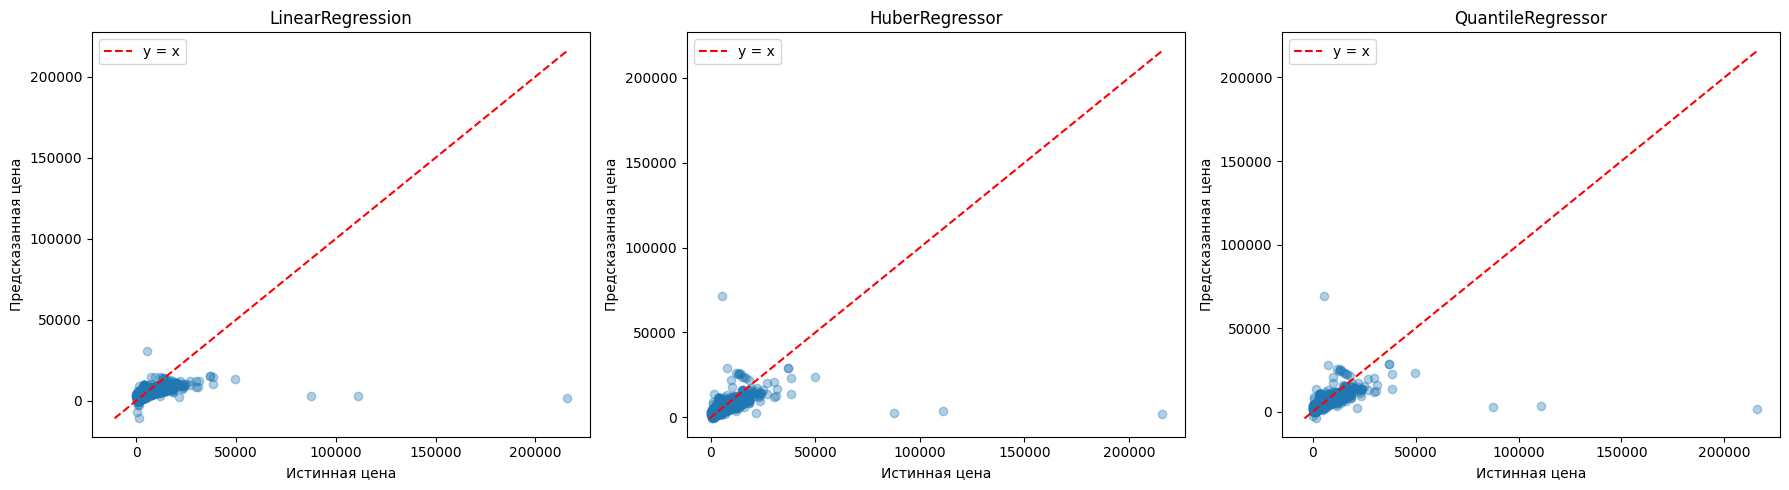

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.35)
    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())
    ax.plot([low, high], [low, high], color='red', linestyle='--', label='y = x')
    ax.set_title(name)
    ax.set_xlabel('Истинная цена')
    ax.set_ylabel('Предсказанная цена')
    ax.legend()

plt.tight_layout()
plt.show()

По результатам сравнения трёх моделей можно сделать вывод, что лучше всего с выбросами справилась QuantileRegressor. У неё самые низкие значения MAE и RMSE, а наибольший R^2. HuberRegressor также показала хорошие результаты и оказалась устойчивее обычной линейной регрессии
При наличии выбросов коэффициенты в обычной линейной регрессии могут сильно смещаться, поскольку модель учитывает квадраты ошибок и особенно чувствительна к большим отклонениям. В результате качество предсказаний снижается, что также отражается на более низком R².

Для задачи оценки стоимости квартир можно сделать вывод, что предварительная очистка данных имеет большое значение
Таким образом, среди рассмотренных моделей лучшие результаты у QuantileRegressor. Предварительную очистку данных всё равно стоит проводить, это позволит избавиться от аномальных значений и не использовать их при обучении модели

## Задание 5. Анализ ошибок по подгруппам и поиск «сложных» сегментов

In [35]:
segment_data = data_raw.dropna().drop_duplicates().drop(columns=['Date']).copy()
segment_info = segment_data[['Type', 'Building', 'Rooms', 'Area']]

X_seg = data_robust.drop(columns=['Price'])
y_seg = data_robust['Price']
X_train_seg, X_test_seg, y_train_seg, y_test_seg = train_test_split(
    X_seg, y_seg, test_size=0.2, random_state=42
)
segment_model = LinearRegression()
segment_model.fit(X_train_seg, y_train_seg)
pred_seg = segment_model.predict(X_test_seg)

test_info = segment_info.loc[X_test_seg.index].copy()
test_info['Истинная цена'] = y_test_seg
test_info['Предсказанная цена'] = pred_seg
test_info['Абсолютная ошибка'] = np.abs(
    test_info['Истинная цена'] - test_info['Предсказанная цена']
)
test_info['Относительная ошибка, %'] = (
    test_info['Абсолютная ошибка'] /
    np.maximum(np.abs(test_info['Истинная цена']), 1e-10) * 100
)

test_info['Квартиль площади'] = pd.qcut(
    test_info['Area'], q=4, duplicates='drop'
)
test_info['Студия'] = np.where(test_info['Rooms'] == 0, 'Студия', 'Не студия')

display(test_info.head())


,Type,Building,Rooms,Area,Истинная цена,Предсказанная цена,Абсолютная ошибка,"Относительная ошибка, %",Квартиль площади,Студия
30806,Resale,Brick,2.0,42.00,2150.00,2879.762012,729.762012,33.942419,"(37.0, 46.0]",Не студия
7094,Resale,Wooden,2.0,43.00,2100.00,2198.833689,98.833689,4.706366,"(37.0, 46.0]",Не студия
26290,Resale,Monolithic,1.0,34.00,2100.00,2484.589691,384.589691,18.313795,"(4.999, 37.0]",Не студия
69077,New,Brick,1.0,43.21,2851.86,2971.302937,119.442937,4.188247,"(37.0, 46.0]",Не студия
3955,Resale,Brick,2.0,40.00,2250.00,2744.327122,494.327122,21.970094,"(37.0, 46.0]",Не студия


In [36]:
group_columns = {
    'Тип продажи': 'Type',
    'Тип дома': 'Building',
    'Количество комнат': 'Rooms',
    'Квартиль площади': 'Квартиль площади',
    'Наличие студии': 'Студия'
}

segment_results = []

for group_name, column in group_columns.items():
    for value, group in test_info.groupby(column, observed=True):
        segment_results.append({
            'Группировка': group_name,
            'Сегмент': str(value),
            'Количество объектов': len(group),
            'MAE': group['Абсолютная ошибка'].mean(),
            'RMSE': np.sqrt(mean_squared_error(
                group['Истинная цена'], group['Предсказанная цена']
            )),
            'Средняя относительная ошибка, %':
                group['Относительная ошибка, %'].mean()
        })

segment_results = pd.DataFrame(segment_results)
display(segment_results.round(3))

,Группировка,Сегмент,Количество объектов,MAE,RMSE,"Средняя относительная ошибка, %"
0,Тип продажи,New,1595,748.851,1465.639,142.983
1,Тип продажи,Resale,12636,754.864,2651.174,49.726
2,Тип дома,Block,407,627.460,901.308,28.075
3,Тип дома,Brick,10441,807.664,2904.096,73.651
4,Тип дома,Monolithic,887,890.565,1767.616,25.867
5,Тип дома,Panel,2420,495.886,648.444,19.278
6,Тип дома,Wooden,76,719.913,921.239,83.837
7,Количество комнат,0.0,167,794.548,1051.034,67.436
8,Количество комнат,1.0,5077,471.605,3067.961,61.653
9,Количество комнат,2.0,5027,646.121,2160.698,84.769


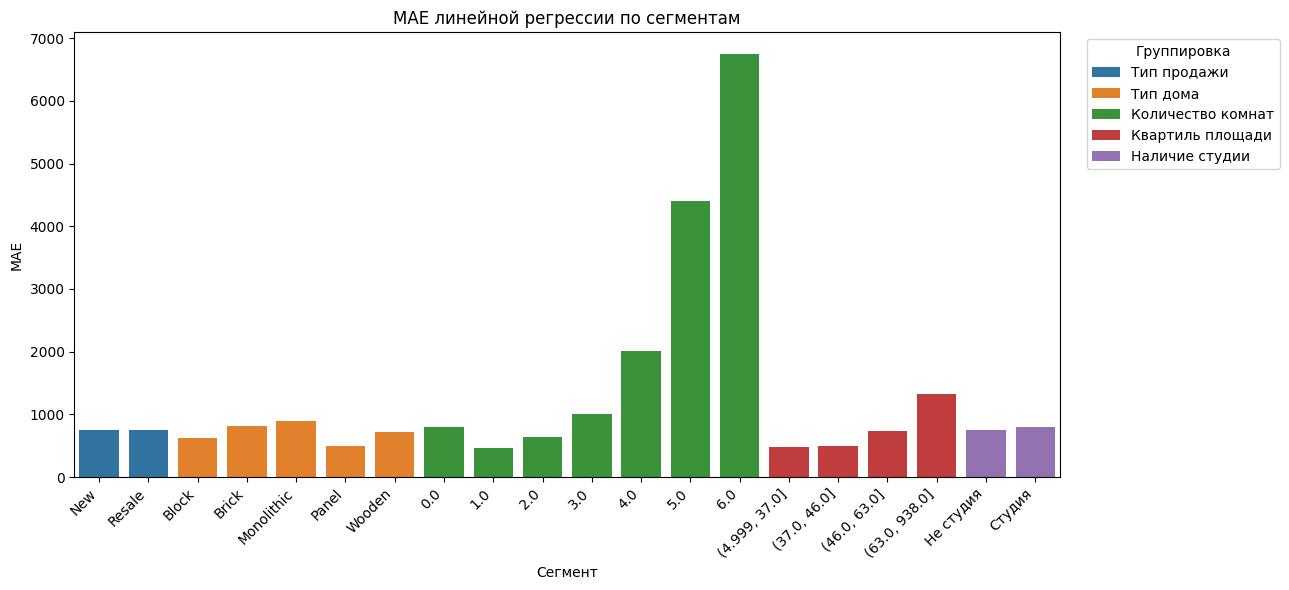

In [37]:
plt.figure(figsize=(13, 6))
sns.barplot(
    data=segment_results,
    x='Сегмент',
    y='MAE',
    hue='Группировка'
)
plt.title('MAE линейной регрессии по сегментам')
plt.xlabel('Сегмент')
plt.ylabel('MAE')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Группировка', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Модель ошибается по сегментам неравномерно (что видно по таблице и графику). Можно определить сегменты, в которых модель ошибается сильнее: квартиры с большой площадью и большим количеством комнат, квартиры в новостройках. Возможные причины различий: у новостроек и вторичного жилья может отличаться структура ценообразования большие квартиры редкие (что можно видеть по количеству объектов в таблице) и иметь более широкий диапазон цен, а также линейная модель может учитывать не все характеристики квартир (например расположение относительно центра и инфраструктуру).
Идеи по улучшению модели:
1. Можно попробовать построить отдельную модель для новостроек и вторичного жилья, проверить насколько велика разница между этими сегментами.
2. Добавить дополнительные признаки расположения жилья (расположение относительно центра, расстояние до метро и социальной инфраструктуры).
3. Попробовать логарифмировать цену, чтобы уменьшить влияние очень дорогих объектов

## Задание 6. Полиномиальные признаки и борьба с переобучением

In [38]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso

target_feature = 'Price'
X_poly_base = data.drop(columns=[target_feature]).copy()
y_poly = data[target_feature].copy()

numeric_features = [
    col for col in ['Area', 'Rooms', 'Floor', 'Floors', 'Lat', 'Lng']
    if col in X_poly_base.columns
]
other_features = [col for col in X_poly_base.columns if col not in numeric_features]

poly = PolynomialFeatures(degree=2, include_bias=False)
X_numeric_poly = poly.fit_transform(X_poly_base[numeric_features])
poly_names = poly.get_feature_names_out(numeric_features)

X_numeric_poly = pd.DataFrame(
    X_numeric_poly, columns=poly_names, index=X_poly_base.index
)
X_poly = pd.concat(
    [X_numeric_poly, X_poly_base[other_features]], axis=1
)

X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_poly, y_poly, test_size=0.2, random_state=42
)

print('Исходное количество признаков:', X_poly_base.shape[1])
print('Количество признаков после преобразования:', X_poly.shape[1])
display(X_poly.columns)

Исходное количество признаков: 11
Количество признаков после преобразования: 32


Index(['Area', 'Rooms', 'Floor', 'Floors', 'Lat', 'Lng', 'Area^2',
       'Area Rooms', 'Area Floor', 'Area Floors', 'Area Lat', 'Area Lng',
       'Rooms^2', 'Rooms Floor', 'Rooms Floors', 'Rooms Lat', 'Rooms Lng',
       'Floor^2', 'Floor Floors', 'Floor Lat', 'Floor Lng', 'Floors^2',
       'Floors Lat', 'Floors Lng', 'Lat^2', 'Lat Lng', 'Lng^2',
       'Building_Brick', 'Building_Monolithic', 'Building_Panel',
       'Building_Wooden', 'Type_Resale'],
      dtype='object')

In [39]:
X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(
    X_poly_base, y_poly, test_size=0.2, random_state=42
)

base_model_poly = LinearRegression()
base_model_poly.fit(X_train_base, y_train_base)
base_pred = base_model_poly.predict(X_test_base)

poly_lr = LinearRegression()
poly_lr.fit(X_train_poly, y_train_poly)

models_poly = {'Polynomial LinearRegression': poly_lr}
alphas = [0.01, 0.1, 1, 10, 100]

for alpha in alphas:
    models_poly[f'Ridge alpha={alpha}'] = make_pipeline(
        StandardScaler(), Ridge(alpha=alpha)
    )
    models_poly[f'Lasso alpha={alpha}'] = make_pipeline(
        StandardScaler(), Lasso(alpha=alpha, max_iter=100000)
    )

poly_results = [{
    'Модель': 'Базовая LinearRegression',
    'RMSE train': np.sqrt(mean_squared_error(
        y_train_base, base_model_poly.predict(X_train_base)
    )),
    'RMSE test': np.sqrt(mean_squared_error(y_test_base, base_pred)),
    'R2 test': r2_score(y_test_base, base_pred)
}]

for name, model in models_poly.items():
    model.fit(X_train_poly, y_train_poly)
    pred_train = model.predict(X_train_poly)
    pred_test = model.predict(X_test_poly)

    poly_results.append({
        'Модель': name,
        'RMSE train': np.sqrt(mean_squared_error(y_train_poly, pred_train)),
        'RMSE test': np.sqrt(mean_squared_error(y_test_poly, pred_test)),
        'R2 test': r2_score(y_test_poly, pred_test)
    })

poly_results = pd.DataFrame(poly_results)
display(poly_results.round(4))

c:\Users\sirda\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.375e+10, tolerance: 1.719e+07
  model = cd_fast.enet_coordinate_descent(


,Модель,RMSE train,RMSE test,R2 test
0,Базовая LinearRegression,793.2492,788.6315,0.7975
1,Polynomial LinearRegression,766.7690,762.5063,0.8107
2,Ridge alpha=0.01,768.6948,765.3616,0.8092
3,Lasso alpha=0.01,775.1344,773.8864,0.8050
4,Ridge alpha=0.1,772.3338,770.6187,0.8066
5,Lasso alpha=0.1,778.8149,777.4086,0.8032
6,Ridge alpha=1,776.9952,775.8935,0.8039
7,Lasso alpha=1,779.3880,778.2123,0.8028
8,Ridge alpha=10,778.7106,777.3900,0.8032
9,Lasso alpha=10,785.1378,782.7553,0.8005


График зависимости тестового RMSE от alpha

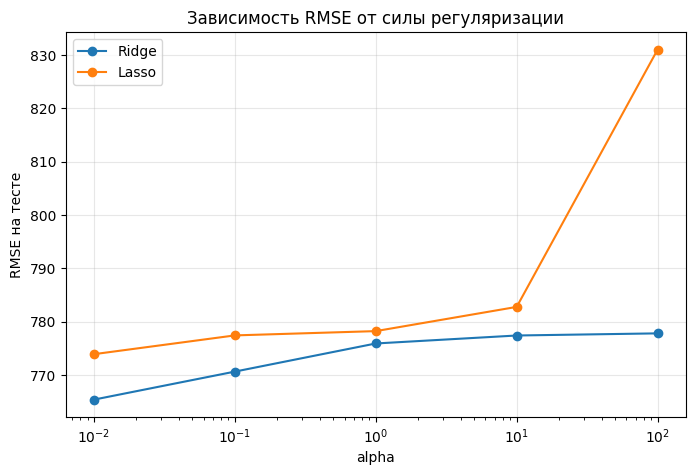

In [40]:
ridge_results = poly_results[
    poly_results['Модель'].str.startswith('Ridge')
]
lasso_results = poly_results[
    poly_results['Модель'].str.startswith('Lasso')
]

plt.figure(figsize=(8, 5))

plt.plot(
    alphas,
    ridge_results['RMSE test'],
    marker='o',
    label='Ridge'
)

plt.plot(
    alphas,
    lasso_results['RMSE test'],
    marker='o',
    label='Lasso'
)

plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('RMSE на тесте')
plt.title('Зависимость RMSE от силы регуляризации')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [41]:
lasso_results = poly_results[
    poly_results['Модель'].str.startswith('Lasso')
]
best_lasso_name = lasso_results.loc[lasso_results['RMSE test'].idxmin(), 'Модель']
best_lasso = models_poly[best_lasso_name]

lasso_coefs = pd.Series(
    best_lasso.named_steps['lasso'].coef_,
    index=X_train_poly.columns
)

nonzero_coefs = lasso_coefs[lasso_coefs.abs() > 1e-8]
zero_coefs = lasso_coefs[lasso_coefs.abs() <= 1e-8]

print('Оптимальная модель Lasso:', best_lasso_name)
print('Количество ненулевых коэффициентов:', len(nonzero_coefs), 'из', len(lasso_coefs))
print('Признаки, выключенные Lasso:')
display(zero_coefs.index.to_list())

Оптимальная модель Lasso: Lasso alpha=0.01
Количество ненулевых коэффициентов: 30 из 32
Признаки, выключенные Lasso:


['Floor Lat', 'Floor Lng']

Оптимальной моделью среди рассмотренных вариантов оказалась Lasso с параметром регуляризации alpha = 0.01. При данном значении модель сохранила 31 из 32 признаков, обнулив только коэффициент признака Floor Lng.
Значит Lasso практически не сократила количество используемых признаков, но определила, что взаимодействие между признаками Floor и Lng не вносит существенного вклада в прогнозирование стоимости квартиры. Остальные признаки остались в модели.

## Задание 7. Логарифмирование целевой переменной и интерпретация коэффициентов

In [42]:
X_task7 = data.drop(columns=['Price']).copy()
y_task7 = data['Price'].copy()

X_train7, X_test7, y_train7, y_test7 = train_test_split(
    X_task7, y_task7, test_size=0.2, random_state=42
)

model_price = LinearRegression()
model_price.fit(X_train7, y_train7)
pred_price = model_price.predict(X_test7)

model_log_price = LinearRegression()
model_log_price.fit(X_train7, np.log1p(y_train7))
pred_log_price = np.expm1(model_log_price.predict(X_test7))

X_interaction = X_task7.copy()
X_interaction['Is_studio'] = (X_interaction['Rooms'] == 0).astype(int)
X_interaction['Floor_ratio'] = (
    X_interaction['Floor'] / X_interaction['Floors'].replace(0, np.nan)
)
X_interaction['Floor_ratio'] = X_interaction['Floor_ratio'].replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

X_interaction['Area * Rooms'] = (
    X_interaction['Area'] * X_interaction['Rooms']
)
X_interaction['Area * Is_studio'] = (
    X_interaction['Area'] * X_interaction['Is_studio']
)
X_interaction['Floor_ratio * Area'] = (
    X_interaction['Floor_ratio'] * X_interaction['Area']
)

X_train_int = X_interaction.loc[X_train7.index]
X_test_int = X_interaction.loc[X_test7.index]

model_interaction = LinearRegression()
model_interaction.fit(X_train_int, y_train7)
pred_interaction = model_interaction.predict(X_test_int)

In [43]:
predictions = {
    'LinearRegression (base)': pred_price,
    'LinearRegression (log Price)': pred_log_price,
    'LinearRegression (взаимодействия)': pred_interaction
}

results = []
for name, pred in predictions.items():
    results.append({
        'Модель': name,
        'MAE': mean_absolute_error(y_test7, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test7, pred)),
        'R2': r2_score(y_test7, pred)
    })

results = pd.DataFrame(results).set_index('Модель')
display(results.round(4))

,MAE,RMSE,R2
Модель,,,
LinearRegression (base),484.9204,788.6315,0.7975
LinearRegression (log Price),516.3566,993.3232,0.6787
LinearRegression (взаимодействия),483.5506,787.5632,0.7980


In [44]:
best_name = results['RMSE'].idxmin()
print('Лучшая модель по RMSE:', best_name)

if best_name == 'LinearRegression (log1p Price)':
    best_model = model_log_price
    best_features = X_train.columns
    coef_scale = 'log1p(Price)'
elif best_name == 'LinearRegression + interactions':
    best_model = model_interaction
    best_features = X_train_int.columns
    coef_scale = 'Price'
else:
    best_model = model_price
    best_features = X_train7.columns
    coef_scale = 'Price'

coef_table = pd.DataFrame({
    'Признак': best_features,
    'Коэффициент': best_model.coef_
})
coef_table['Модуль коэффициента'] = coef_table['Коэффициент'].abs()
coef_table = coef_table.sort_values(
    'Модуль коэффициента', ascending=False
)

print('Шкала коэффициентов:', coef_scale)
display(coef_table.head(15).drop(columns='Модуль коэффициента'))


Лучшая модель по RMSE: LinearRegression (взаимодействия)
Шкала коэффициентов: Price


,Признак,Коэффициент
1,Lng,2736.596917
0,Lat,1477.156939
9,Building_Wooden,-768.963807
3,Rooms,-402.954221
10,Type_Resale,189.048687
5,Area,80.362131
8,Building_Panel,-60.716514
6,Building_Brick,39.657552
7,Building_Monolithic,-33.400925
2,Floors,20.393177


Модель с логарифмом цены не привела к улучшению метрик. В качестве лучшей выбрана модель с взаимодействиями,

Параметры можно интерпретировать как типичное изменение цены квартиры при изменении параметра на единицу (при неизменных остальных параметрах). При интерпретации нужно учитывать что параметры имеют разный диапазон значений.

Анализ коэффициентов показал, что наибольший коэффициент у географических координат квартиры Lng и Lat (но они изменяются достаточно незначитильно). Площадь Area имеет положительное влияние на стоимость, что мы и ожидаем. Среди категориальных признаков отрицательный коэффициент получен для деревянных домов Building_Wooden, а положительный — для вторичного жилья Type_Resale.

В итоге: добавление взаимодействий между признаками позволило получить наиболее точную модель среди рассмотренных вариантов. Это показывает, что зависимость стоимости квартиры от характеристик жилья может быть сложнее, чем простая линейная зависимость каждого признака по отдельности